In [2]:
# Generate tax data
# Generate tax data with 100 points with only 1 slab such as income > 10000 with a tax of 20%.

"""
Generate synthetic tax data: 100 points, one tax slab.

Rule: income up to 10,000 is tax-free; income above 10,000 is taxed at 20%.
      tax = 0.20 * max(0, income - 10000)
"""

import numpy as np
import pandas as pd

N_POINTS = 100
THRESHOLD = 10_000
RATE = 0.20

rng = np.random.default_rng(seed=42)  # fixed seed so the data is reproducible

# Incomes spread on both sides of the threshold
income = rng.uniform(0, 30_000, N_POINTS).round(2)

# Tax applies only to the portion above the threshold
tax = (RATE * np.maximum(0, income - THRESHOLD)).round(2)

df = pd.DataFrame({"income": income, "tax": tax})
df.to_csv("tax_data.csv", index=False)

print(df.head(10))
print(f"\nRows: {len(df)}")
print(f"Rows with income > {THRESHOLD}: {(df.income > THRESHOLD).sum()}")
print("Saved to tax_data.csv")

     income      tax
0  23218.68  2643.74
1  13166.35   633.27
2  25757.94  3151.59
3  20921.04  2184.21
4   2825.32     0.00
5  29268.67  3853.73
6  22834.19  2566.84
7  23581.93  2716.39
8   3843.41     0.00
9  13511.58   702.32

Rows: 100
Rows with income > 10000: 67
Saved to tax_data.csv


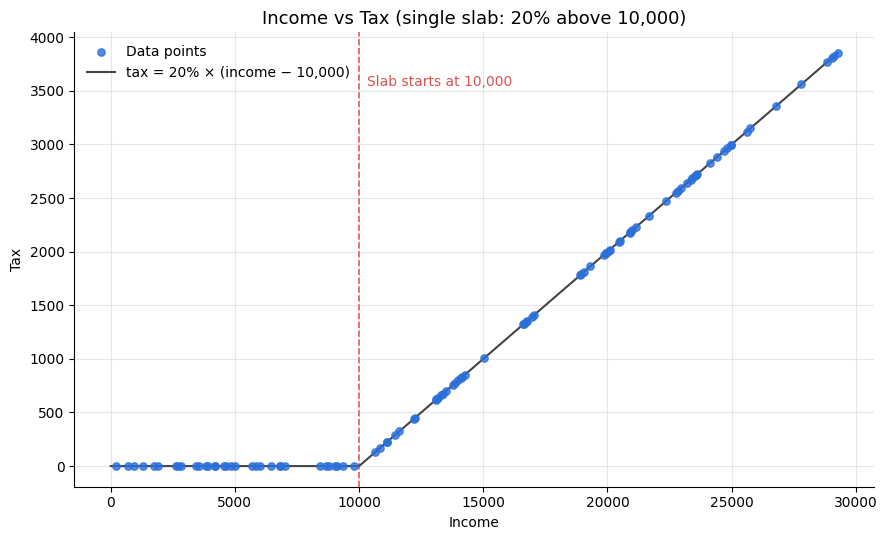

In [2]:
# write python code to visualize it
"""
Visualize the tax data from tax_data.csv: income vs tax, with the 10,000 slab marked.
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

THRESHOLD = 10_000
RATE = 0.20

df = pd.read_csv("tax_data.csv")

fig, ax = plt.subplots(figsize=(9, 5.5))

# Data points
ax.scatter(df.income, df.tax, s=28, color="#2a6fdb", alpha=0.8, label="Data points", zorder=3)

# The true tax rule as a line
x = np.linspace(0, df.income.max(), 500)
ax.plot(x, RATE * np.maximum(0, x - THRESHOLD), color="#444", lw=1.5,
        label="tax = 20% × (income − 10,000)", zorder=2)

# Threshold marker
ax.axvline(THRESHOLD, color="#d9534f", ls="--", lw=1.2, zorder=1)
ax.text(THRESHOLD + 300, df.tax.max() * 0.92, "Slab starts at 10,000",
        color="#d9534f", fontsize=10)

ax.set_title("Income vs Tax (single slab: 20% above 10,000)", fontsize=13)
ax.set_xlabel("Income")
ax.set_ylabel("Tax")
ax.grid(True, alpha=0.3)
ax.legend(loc="upper left", frameon=False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.savefig("tax_plot.png", dpi=150)
plt.show()

In [ ]:
# Assignment: Try fitting in the logistic regression and notice the error.


In [ ]:
Income(X) and Tax (y), Is_taxable(y > 0)

Is_taxable = y > 0
classifier.fit(X, is_taxable)

X_taxable = X[y>0]
Tax_taxable = y[y>0]

compute_tax_taxable.fit(X_taxable, Tax_taxable)

def prediction(Income):
    if is_taxable(income):
        return compute_tax_taxable(income)
    return 0


In [ ]:
def classifier(X, W):
    return sigmoid(X.W)

def regression(X, X_cls, W):
    return np.sum(concatenates(X, X_cls).W)

def loss(X, W1, W2, y):
    c = classifier(X, W1)
    pred_tax =  regression(X, c, W2)
    return np.sum(pred_tax - y)**2

def gradient_step(X, W1, W2, y)
    # compute gradient of loss wrt each weights
    # And update the weights  
    # 

def gradient_descent(X, y):
    W1 = initialize
    W2 = initliaze
    for i in epochs:
        gradient_step(X, W1, W2, y)
    


In [11]:
# https://chatgpt.com/share/6add8b1c-20b8-83ea-869d-739f5b347578

In [ ]:
import numpy as np

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))


def classifier(X, W):
    return sigmoid(X @ W)


def regression(X, X_cls, W):
    X_combined = np.column_stack([X, X_cls])
    return (X_combined @ W) * X_cls


def loss(X, W1, W2, y):
    c = classifier(X, W1)
    pred_tax = regression(X, c, W2)
    return np.mean((pred_tax - y) ** 2)


def grad(X, W1, W2, y, epsilon=1e-4):
    """
    Compute numerical gradients by slightly increasing
    each weight and observing the change in loss.
    """
    dW1 = np.zeros_like(W1)
    dW2 = np.zeros_like(W2)

    current_loss = loss(X, W1, W2, y)

    for i in range(len(W1)):
        W1_new = W1.copy()
        W1_new[i] += epsilon

        dW1[i] = (
            loss(X, W1_new, W2, y) - current_loss
        ) / epsilon

    for i in range(len(W2)):
        W2_new = W2.copy()
        W2_new[i] += epsilon

        dW2[i] = (
            loss(X, W1, W2_new, y) - current_loss
        ) / epsilon

    return dW1, dW2


def gradient_step(X, W1, W2, y, learning_rate):
    dW1, dW2 = grad(X, W1, W2, y)

    W1 = W1 - learning_rate * dW1
    W2 = W2 - learning_rate * dW2

    return W1, W2


def gradient_descent(X, y, epochs=5000, learning_rate=0.01):
    rng = np.random.default_rng(42)

    # Classifier: income + bias
    W1 = rng.normal(0, 0.1, size=X.shape[1])

    # Regression: income + bias + classifier output
    W2 = rng.normal(0, 0.1, size=X.shape[1] + 1)

    for i in range(epochs):
        W1, W2 = gradient_step(
            X, W1, W2, y, learning_rate
        )

        if i % 500 == 0:
            print(f"Epoch {i}: Loss = {loss(X, W1, W2, y):.6f}")

    return W1, W2

In [ ]:
%pip install tensorflow

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 3)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10 (40.00 B)

 Trainable params: 10 (40.00 B)

 Non-trainable params: 0 (0.00 B)

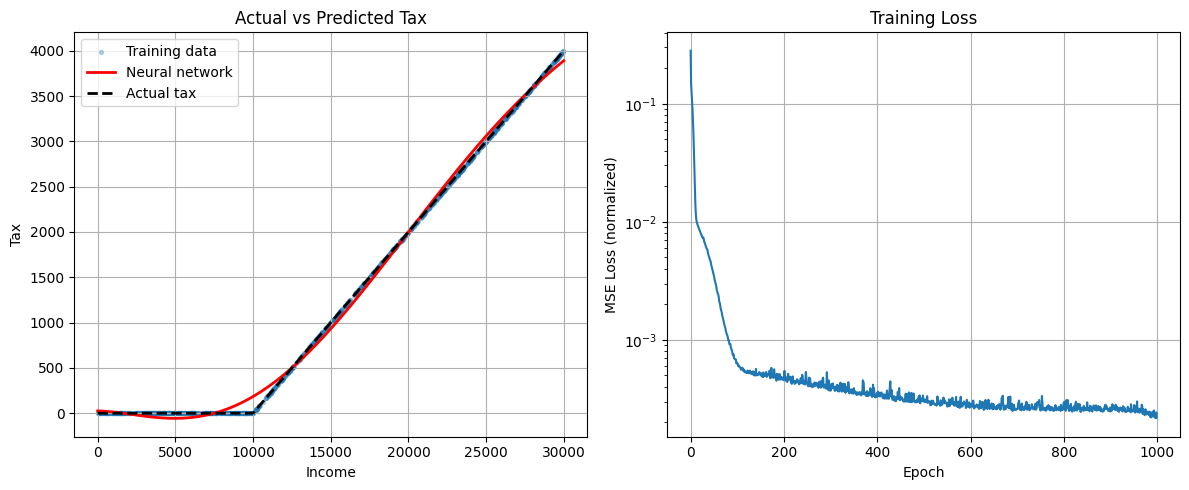

In [9]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# 1. Generate data
rng = np.random.default_rng(42)

N_POINTS = 1000
THRESHOLD = 10000
RATE = 0.20

income = rng.uniform(0, 30_000, N_POINTS).round(2)
tax = (RATE * np.maximum(0, income - THRESHOLD)).round(2)

# 2. Normalize inputs and outputs
X = (income / 30000).reshape(-1, 1).astype("float32")
y = (tax / 4000).reshape(-1, 1).astype("float32")

# 3. Build neural network
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(1,)),
    tf.keras.layers.Dense(3, activation="sigmoid"),
    tf.keras.layers.Dense(1)
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
    loss="mse"
)

model.summary()

# 4. Train
history = model.fit(
    X, y,
    epochs=1000,
    batch_size=32,
    verbose=0
)

# 5. Predict on sorted incomes
test_income = np.linspace(0, 30000, 500)
X_test = (test_income / 30000).reshape(-1, 1)

predicted_tax = model.predict(X_test, verbose=0).flatten() * 4000

actual_tax = RATE * np.maximum(0, test_income - THRESHOLD)

# 6. Visualize
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(income, tax, s=8, alpha=0.3, label="Training data")
plt.plot(test_income, predicted_tax, "r", linewidth=2,
         label="Neural network")
plt.plot(test_income, actual_tax, "k--", linewidth=2,
         label="Actual tax")
plt.xlabel("Income")
plt.ylabel("Tax")
plt.legend()
plt.grid(True)
plt.title("Actual vs Predicted Tax")

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"])
plt.xlabel("Epoch")
plt.ylabel("MSE Loss (normalized)")
plt.title("Training Loss")
plt.yscale("log")
plt.grid(True)

plt.tight_layout()
plt.show()


In [10]:
# https://chatgpt.com/share/6add8afb-003c-83ea-bb94-5d989d7d90a8

In [ ]:
X --> L1 + L2 + L3 + L4 --> y

In [ ]:
Except for last layer, use activation function (sigmoid, )
    # if value > 0, return 1 else return 0

In [1]:
# In regression, no activation in last layer.

# IN binary classification, sigmoid in last layer

# In multilabel binary classification:
    - is person happy
    - is male

last layer will have how many neurons - 2
What activation would like use in last layer: sigmoid 

# In multiclass classification:
    * Softmax 



IndentationError: unexpected indent (4139800369.py, line 6)

In [ ]:
A system needs to produce the 

1. bounding box of the object found:
    - Cordinates of center 
    - width and height of the box 

2. What is there in the box? 
    - Man 
    - cow 
    - cycle
    - ...
    -- 1000 classes 

3. 